In [7]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [10]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/content/file_1791938376200_HomePricesData.csv")

In [11]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nTypes and non-null counts:")
df.info()

print("\nMissing values per column:")
print(df.isna().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())
display(df.head(8))

Shape: (154, 4)

Column names:
['area', 'bedrooms', 'age', 'price']

Types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 154 entries, 0 to 153
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   area      152 non-null    object
 1   bedrooms  145 non-null    object
 2   age       147 non-null    object
 3   price     148 non-null    object
dtypes: object(4)
memory usage: 4.9+ KB

Missing values per column:
bedrooms    9
age         7
price       6
area        2
dtype: int64

Duplicate rows: 3


,area,bedrooms,age,price
0,2600,3,20,550000
1,3000,4,15,565000
2,3200,NaN,18,610000
3,3600,3,30,595000
4,4000,5,8,760000
5,4100,6,8,810000
6,154 m2,3,-60,56654
7,570 m2,three,23,"724,781"


In [15]:
df_clean = df.copy()

# Keep the original area text so you can check the conversion
df_clean["area_original"] = df_clean["area"]

area_text = df_clean["area"].astype("string").str.strip().str.lower()

# Extract the number, allowing commas such as "4,598"
area_number = pd.to_numeric(
    area_text.str.replace(",", "", regex=False)
             .str.extract(r"(-?\d+(?:\.\d+)?)", expand=False),
    errors="coerce"
).astype("float64")

# Convert square metres to square feet; leave sqft and plain numbers unchanged
is_square_metres = area_text.str.contains(r"m2|m²", na=False)
df_clean["area"] = area_number.where(
    ~is_square_metres,
    area_number * 10.7639
)

display(df_clean[["area_original", "area"]].head(20))

,area_original,area
0,2600,2600.0000
1,3000,3000.0000
2,3200,3200.0000
3,3600,3600.0000
4,4000,4000.0000
5,4100,4100.0000
6,154 m2,1657.6406
7,570 m2,6135.4230
8,930 sqft,930.0000
9,1984 sqft,1984.0000


In [16]:
df_clean["bedrooms_original"] = df_clean["bedrooms"]

bedrooms_text = (
    df_clean["bedrooms"]
    .astype("string")
    .str.strip()
    .str.lower()
)

word_to_number = {
    "one": "1",
    "two": "2",
    "three": "3",
    "four": "4",
    "five": "5",
    "six": "6",
}

bedrooms_text = bedrooms_text.replace(word_to_number)
df_clean["bedrooms"] = pd.to_numeric(bedrooms_text, errors="coerce")

display(df_clean[["bedrooms_original", "bedrooms"]].head(20))

,bedrooms_original,bedrooms
0,3,3.0
1,4,4.0
2,NaN,<NA>
3,3,3.0
4,5,5.0
5,6,6.0
6,3,3.0
7,three,3.0
8,six,6.0
9,4.0,4.0


In [17]:
df_clean["age_original"] = df_clean["age"]

age_text = (
    df_clean["age"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s*years?\s*$", "", regex=True)
    .replace({"twenty": "20"})
)

df_clean["age"] = pd.to_numeric(age_text, errors="coerce")

display(df_clean[["age_original", "age"]].head(25))

,age_original,age
0,20,20
1,15,15
2,18,18
3,30,30
4,8,8
5,8,8
6,-60,-60
7,23,23
8,52,52
9,57,57


In [18]:
df_clean["price_original"] = df_clean["price"]

price_text = (
    df_clean["price"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"usd|\$", "", regex=True)
    .str.replace(",", "", regex=False)
    .str.strip()
)

# Remember which values use "k" before removing the suffix
has_k = price_text.str.endswith("k", na=False)
price_text = price_text.str.replace(r"k$", "", regex=True)

price_number = pd.to_numeric(price_text, errors="coerce")
df_clean["price"] = price_number.where(~has_k, price_number * 1000)

display(df_clean[["price_original", "price"]].head(25))

,price_original,price
0,550000,550000.0
1,565000,565000.0
2,610000,610000.0
3,595000,595000.0
4,760000,760000.0
5,810000,810000.0
6,56654,56654.0
7,"724,781",724781.0
8,USD 65778,65778.0
9,134610,134610.0


In [19]:
possible_problems = df_clean.loc[
    (df_clean["area"] <= 0)
    | (df_clean["bedrooms"] <= 0)
    | (df_clean["age"] < 0)
    | (df_clean["price"] <= 0),
    [
        "area_original", "area",
        "bedrooms_original", "bedrooms",
        "age_original", "age",
        "price_original", "price",
    ],
]

display(possible_problems)

,area_original,area,bedrooms_original,bedrooms,age_original,age,price_original,price
6,154 m2,1657.6406,3,3.0,-60,-60,56654,56654.0
48,"5,972",5972.0000,four,4.0,-31,-31,"$705,388",705388.0
50,NaN,NaN,1,1.0,-37,-37,"$512,549",512549.0
54,0,0.0000,4,4.0,32 years,32,"-444,790",-444790.0
57,1423,1423.0000,1,1.0,59,59,-3741,-3741.0
66,5535,5535.0000,1,1.0,-47,-47,USD 503215,503215.0
75,165 m2,1776.0435,1,1.0,-17,-17,"$190,726",190726.0
107,2368,2368.0000,1,1.0,-60,-60,USD 173703,173703.0


In [20]:
# Parse the original age values again
age_from_original = (
    df_clean["age_original"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s*years?\s*$", "", regex=True)
    .replace({"twenty": "20"})
)
age_from_original = pd.to_numeric(age_from_original, errors="coerce")

# Parse the original price values again
price_text = (
    df_clean["price_original"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"usd|\$", "", regex=True)
    .str.replace(",", "", regex=False)
    .str.strip()
)

has_k = price_text.str.endswith("k", na=False)
price_text = price_text.str.replace(r"k$", "", regex=True)
price_from_original = pd.to_numeric(price_text, errors="coerce")
price_from_original = price_from_original.where(
    ~has_k, price_from_original * 1000
)

# Show proposed positive versions, without changing df_clean
negative_rows = age_from_original.lt(0) | price_from_original.lt(0)

review = df_clean.loc[
    negative_rows,
    ["area_original", "bedrooms_original", "age_original", "price_original"]
].copy()

review["age_candidate"] = age_from_original.loc[negative_rows].abs()
review["price_candidate"] = price_from_original.loc[negative_rows].abs()

display(review)

,area_original,bedrooms_original,age_original,price_original,age_candidate,price_candidate
6,154 m2,3,-60,56654,60,56654.0
48,"5,972",four,-31,"$705,388",31,705388.0
50,NaN,1,-37,"$512,549",37,512549.0
54,0,4,32 years,"-444,790",32,444790.0
57,1423,1,59,-3741,59,3741.0
66,5535,1,-47,USD 503215,47,503215.0
75,165 m2,1,-17,"$190,726",17,190726.0
107,2368,1,-60,USD 173703,60,173703.0


In [21]:
# Find negative values using the parsed original columns
negative_age = age_from_original < 0
negative_price = price_from_original < 0

# Replace them with their positive versions
df_clean.loc[negative_age, "age"] = age_from_original.loc[negative_age].abs()
df_clean.loc[negative_price, "price"] = price_from_original.loc[negative_price].abs()

# Check the corrected values against the originals
display(
    df_clean.loc[
        negative_age | negative_price,
        ["age_original", "age", "price_original", "price"]
    ]
)

,age_original,age,price_original,price
6,-60,60,56654,56654.0
48,-31,31,"$705,388",705388.0
50,-37,37,"$512,549",512549.0
54,32 years,32,"-444,790",444790.0
57,59,59,-3741,3741.0
66,-47,47,USD 503215,503215.0
75,-17,17,"$190,726",190726.0
107,-60,60,USD 173703,173703.0


In [22]:
print("Missing values in cleaned columns:")
display(df_clean[["area", "bedrooms", "age", "price"]].isna().sum())

original_columns = [
    "area_original",
    "bedrooms_original",
    "age_original",
    "price_original",
]

duplicate_mask = df_clean.duplicated(
    subset=original_columns,
    keep=False
)

print("Rows that are exact duplicates in the original data:")
display(df_clean.loc[duplicate_mask, original_columns])

Missing values in cleaned columns:


,0
area,3
bedrooms,9
age,7
price,6


Rows that are exact duplicates in the original data:


,area_original,bedrooms_original,age_original,price_original
20,106 m2,5.0,23 years,123903
35,318 m2,2,44 years,"290,206"
52,106 m2,5.0,23 years,123903
60,3055 sqft,3.0,19,"$348,812"
95,318 m2,2,44 years,"290,206"
134,3055 sqft,3.0,19,"$348,812"


In [23]:
rows_before = len(df_clean)

df_clean = df_clean.drop_duplicates(
    subset=original_columns,
    keep="first"
).copy()

print("Duplicate copies removed:", rows_before - len(df_clean))
print("Rows remaining:", len(df_clean))

Duplicate copies removed: 3
Rows remaining: 151


In [24]:
clean_columns = ["area", "bedrooms", "age", "price"]

print("Missing values per column:")
print(df_clean[clean_columns].isna().sum())

print("\nRows with at least one missing value:")
display(df_clean.loc[df_clean[clean_columns].isna().any(axis=1), clean_columns])

Missing values per column:
area        3
bedrooms    9
age         7
price       6
dtype: int64

Rows with at least one missing value:


,area,bedrooms,age,price
2,3200.0000,<NA>,18,610000.0
24,2295.0000,3.0,7,<NA>
31,5934.0000,2.0,41,<NA>
33,5916.0000,<NA>,22,691789.0
36,2397.0000,1.0,<NA>,232109.0
37,2163.0000,<NA>,61,187708.0
50,NaN,1.0,37,512549.0
61,4791.0000,4.0,<NA>,520171.0
62,2245.0000,<NA>,24,305594.0
73,1862.1547,5.0,<NA>,199950.0


In [25]:
df_model = df_clean.dropna(subset=["price"]).copy()

print("Rows in cleaned data:", len(df_clean))
print("Rows with a known price:", len(df_model))
print("\nMissing values in modeling data:")
print(df_model[["area", "bedrooms", "age", "price"]].isna().sum())

Rows in cleaned data: 151
Rows with a known price: 145

Missing values in modeling data:
area        2
bedrooms    8
age         7
price       0
dtype: int64


In [26]:
print("Area median:", df_model["area"].median())
print("Age median:", df_model["age"].median())
print("Most common bedroom count(s):")
print(df_model["bedrooms"].mode().tolist())

Area median: 3873.0
Age median: 29.0
Most common bedroom count(s):
[1.0]


In [27]:
df_model["area"] = df_model["area"].fillna(df_model["area"].median())
df_model["age"] = df_model["age"].fillna(df_model["age"].median())
df_model["bedrooms"] = df_model["bedrooms"].fillna(
    df_model["bedrooms"].mode()[0]
)

print("Missing values after filling:")
print(df_model[["area", "bedrooms", "age", "price"]].isna().sum())

Missing values after filling:
area        0
bedrooms    0
age         0
price       0
dtype: int64


In [28]:
print("Lowest prices:")
display(
    df_model.sort_values("price")[
        ["area", "bedrooms", "age", "price", "price_original"]
    ].head(10)
)

print("Highest prices:")
display(
    df_model.sort_values("price", ascending=False)[
        ["area", "bedrooms", "age", "price", "price_original"]
    ].head(10)
)

print("\nPrice summary:")
display(df_model["price"].describe())

Lowest prices:


,area,bedrooms,age,price,price_original
57,1423.0000,1.0,59,3741.0,-3741
131,1299.0000,1.0,44,15703.0,"$15,703"
139,933.0000,1.0,43,42571.0,"42,571"
6,1657.6406,3.0,60,56654.0,56654
8,930.0000,6.0,52,65778.0,USD 65778
120,1498.0000,3.0,48,88497.0,USD 88497
21,1179.0000,5.0,40,97700.0,97.7k
136,1694.0000,1.0,38,122323.0,122323
20,1140.9734,5.0,23,123903.0,123903
70,1759.0000,1.0,60,131088.0,131088


Highest prices:


,area,bedrooms,age,price,price_original
18,16629.000,2.0,3,1228187.0,1228187
153,3873.000,5.0,29,999999.0,USD 999999
5,4100.000,6.0,8,810000.0,810000
89,6491.000,4.0,4,763236.0,"763,236"
4,4000.000,5.0,8,760000.0,760000
29,6381.000,3.0,0,754014.0,754014
7,6135.423,3.0,23,724781.0,"724,781"
126,6134.000,5.0,17,724491.0,"$724,491"
90,6022.000,4.0,29,723059.0,723059
56,6334.000,6.0,41,722577.0,"722,577"



Price summary:


,price
count,145.0
mean,426833.275862
std,206735.187927
min,3741.0
25%,269400.0
50%,421386.0
75%,573535.0
max,1228187.0


In [29]:
df_model["price_per_sqft"] = df_model["price"] / df_model["area"]

print("Lowest price per square foot:")
display(
    df_model.sort_values("price_per_sqft")[
        ["area", "bedrooms", "age", "price", "price_per_sqft", "price_original"]
    ].head(10)
)

Lowest price per square foot:


,area,bedrooms,age,price,price_per_sqft,price_original
57,1423.0000,1.0,59,3741.0,2.628953,-3741
131,1299.0000,1.0,44,15703.0,12.08853,"$15,703"
6,1657.6406,3.0,60,56654.0,34.177493,56654
139,933.0000,1.0,43,42571.0,45.628081,"42,571"
120,1498.0000,3.0,48,88497.0,59.076769,USD 88497
32,2284.0000,3.0,62,148744.0,65.124343,148744
9,1984.0000,4.0,57,134610.0,67.847782,134610
8,930.0000,6.0,52,65778.0,70.729032,USD 65778
136,1694.0000,1.0,38,122323.0,72.209563,122323
107,2368.0000,1.0,60,173703.0,73.354307,USD 173703


In [30]:
display(df.loc[[57, 131]])

,area,bedrooms,age,price
57,1423,1,59,-3741
131,"1,299",1.0,44 years,"$15,703"


In [31]:
suspect_rows = [57, 131]

# Keep the full cleaned data; create a separate copy for analysis
df_model_reviewed = df_model.drop(index=suspect_rows).copy()

print("Rows before excluding suspects:", len(df_model))
print("Rows after excluding suspects:", len(df_model_reviewed))
print("Suspect rows kept in df_clean:", suspect_rows)

Rows before excluding suspects: 145
Rows after excluding suspects: 143
Suspect rows kept in df_clean: [57, 131]


In [32]:
final_columns = ["area", "bedrooms", "age", "price"]

print("Shape:", df_model_reviewed[final_columns].shape)

print("\nData types:")
print(df_model_reviewed[final_columns].dtypes)

print("\nMissing values:")
print(df_model_reviewed[final_columns].isna().sum())

print("\nDuplicate original records:")
print(df_model_reviewed.duplicated(subset=original_columns).sum())

print("\nSummary:")
display(df_model_reviewed[final_columns].describe())

Shape: (143, 4)

Data types:
area        float64
bedrooms    Float64
age           Int64
price       Float64
dtype: object

Missing values:
area        0
bedrooms    0
age         0
price       0
dtype: int64

Duplicate original records:
0

Summary:


,area,bedrooms,age,price
count,143.000000,143.0,143.0,143.0
mean,3905.553794,3.223776,30.622378,432667.0
std,1897.321890,1.781832,18.917465,202129.111918
min,0.000000,1.0,0.0,42571.0
25%,2409.438750,2.0,15.0,283352.5
50%,3873.000000,3.0,29.0,421394.0
75%,5030.500000,5.0,47.0,578086.5
max,16629.000000,6.0,64.0,1228187.0


In [33]:
display(
    df_model_reviewed.loc[
        df_model_reviewed["area"] <= 0,
        ["area_original", "area", "bedrooms", "age", "price"]
    ]
)

,area_original,area,bedrooms,age,price
54,0,0.0,4.0,32,444790.0


In [34]:
print("Rows before:", len(df_model_reviewed))

df_model_reviewed = df_model_reviewed.loc[
    df_model_reviewed["area"] > 0
].copy()

print("Rows after:", len(df_model_reviewed))
print("Rows with non-positive area:", (df_model_reviewed["area"] <= 0).sum())

Rows before: 143
Rows after: 142
Rows with non-positive area: 0


In [35]:
output_file = "HomePricesData_cleaned.csv"

df_model_reviewed[final_columns].to_csv(output_file, index=False)
print(f"Saved {output_file}")

Saved HomePricesData_cleaned.csv


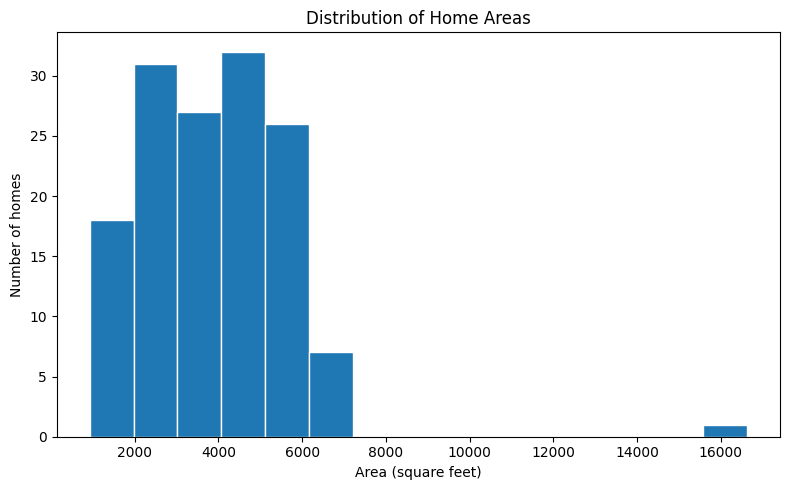

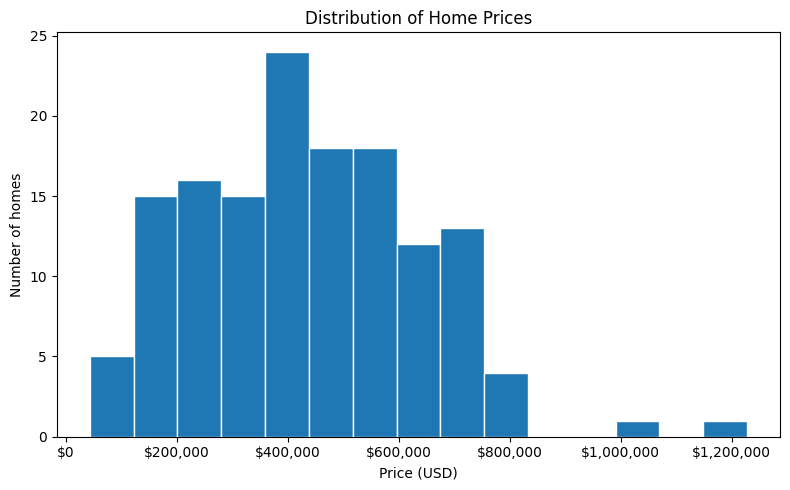

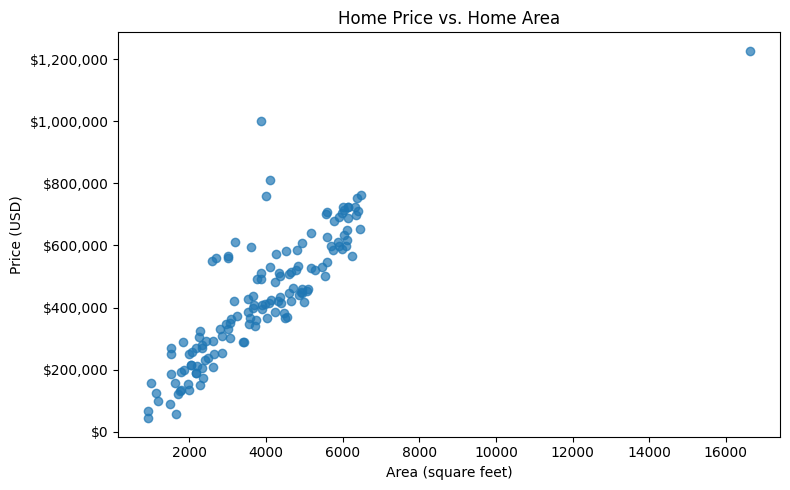

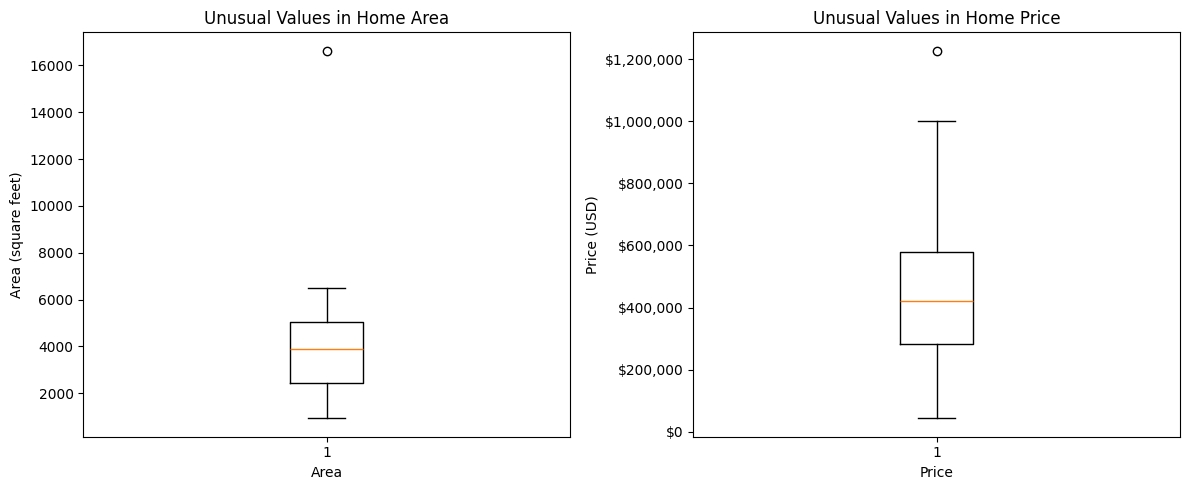

In [47]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# 1. Distribution of home area
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df_model_reviewed["area"], bins=15, edgecolor="white")
ax.set_title("Distribution of Home Areas")
ax.set_xlabel("Area (square feet)")
ax.set_ylabel("Number of homes")
plt.tight_layout()
plt.show()

# 2. Distribution of home prices
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df_model_reviewed["price"], bins=15, edgecolor="white")
ax.set_title("Distribution of Home Prices")
ax.set_xlabel("Price (USD)")
ax.set_ylabel("Number of homes")
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
plt.tight_layout()
plt.show()

# 3. Relationship between area and price
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    df_model_reviewed["area"],
    df_model_reviewed["price"],
    alpha=0.7
)
ax.set_title("Home Price vs. Home Area")
ax.set_xlabel("Area (square feet)")
ax.set_ylabel("Price (USD)")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
plt.tight_layout()
plt.show()

# 4. Boxplots to help spot unusual values
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(df_model_reviewed["area"], showfliers=True)
axes[0].set_title("Unusual Values in Home Area")
axes[0].set_xlabel("Area")
axes[0].set_ylabel("Area (square feet)")

axes[1].boxplot(df_model_reviewed["price"], showfliers=True)
axes[1].set_title("Unusual Values in Home Price")
axes[1].set_xlabel("Price")
axes[1].set_ylabel("Price (USD)")
axes[1].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))

plt.tight_layout()
plt.show()

In [49]:
from sklearn.model_selection import train_test_split

# Start from the cleaned data, but before filling missing input values
model_data = df_clean.dropna(subset=["price"]).copy()

# Keep the two suspicious-price rows out of this analysis
model_data = model_data.drop(index=suspect_rows, errors="ignore")

# Exclude houses with missing or non-positive area
model_data = model_data.loc[model_data["area"] > 0].copy()

# Features are the information used to predict; target is what we predict
X = model_data[["area", "bedrooms", "age"]].astype("float64")
y = model_data["price"]

# Randomly split matching feature rows and prices
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    shuffle=True,
    random_state=42
)

# Learn fill values from the training set only
fill_values = {
    "area": X_train["area"].median(),
    "bedrooms": X_train["bedrooms"].mode()[0],
    "age": X_train["age"].median(),
}

# Apply those training-set values to both sets
X_train = X_train.fillna(fill_values)
X_test = X_test.fillna(fill_values)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nMissing values in training features:")
print(X_train.isna().sum())
print("\nMissing values in testing features:")
print(X_test.isna().sum())

Training rows: 105
Testing rows: 35

Missing values in training features:
area        0
bedrooms    0
age         0
dtype: int64

Missing values in testing features:
area        0
bedrooms    0
age         0
dtype: int64


In [51]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

# Learn the relationship using training data only
model.fit(X_train, y_train)

# Predict prices for the separate test data
y_pred = model.predict(X_test)

print("Model trained.")
print("Number of test predictions:", len(y_pred))

Model trained.
Number of test predictions: 35


In [52]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R²:   {r2:.3f}")
print(f"MAE:  ${mae:,.0f}")
print(f"RMSE: ${rmse:,.0f}")

R²:   0.728
MAE:  $52,418
RMSE: $118,266


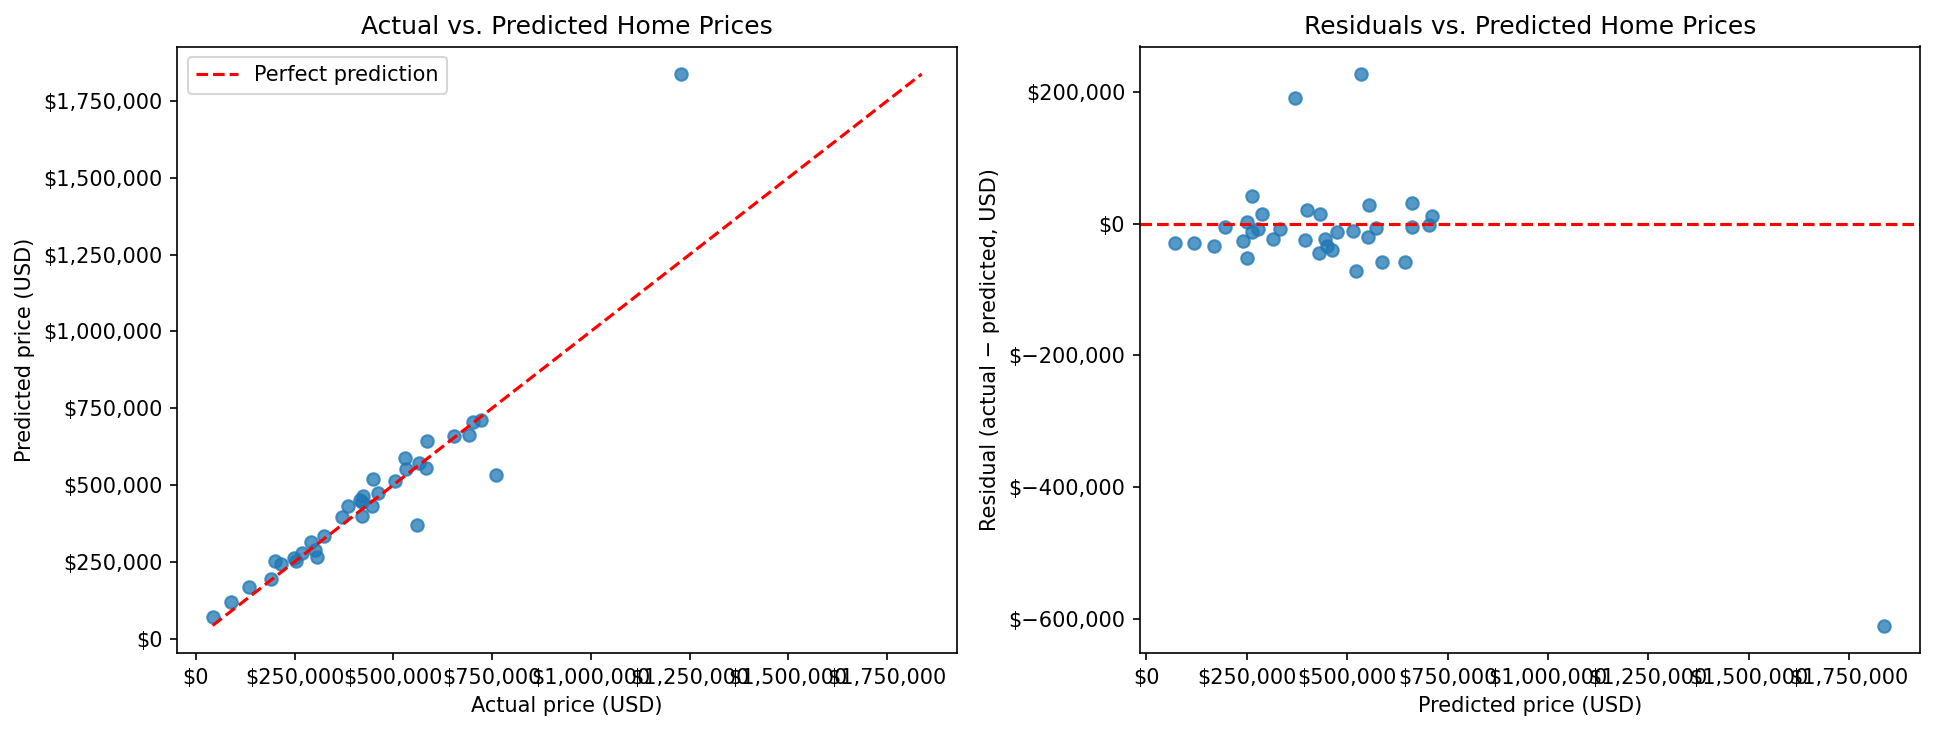

In [55]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual versus predicted
axes[0].scatter(y_test, y_pred, alpha=0.75)
plot_min = min(y_test.min(), y_pred.min())
plot_max = max(y_test.max(), y_pred.max())
axes[0].plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)
axes[0].set_title("Actual vs. Predicted Home Prices")
axes[0].set_xlabel("Actual price (USD)")
axes[0].set_ylabel("Predicted price (USD)")
axes[0].xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[0].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[0].legend()

# Residuals: actual price minus predicted price
residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.75)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs. Predicted Home Prices")
axes[1].set_xlabel("Predicted price (USD)")
axes[1].set_ylabel("Residual (actual − predicted, USD)")
axes[1].xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[1].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))

plt.tight_layout()

from IPython.display import Image, display

fig.savefig("model_diagnostics.png", dpi=150, bbox_inches="tight")
display(Image(filename="model_diagnostics.png"))
plt.close(fig)

In [54]:
coefficient_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient (USD per feature unit)": model.coef_,
})

display(coefficient_table)
print(f"Intercept (USD): ${model.intercept_:,.2f}")

,Feature,Coefficient (USD per feature unit)
0,area,106.709400
1,bedrooms,18993.161484
2,age,-2752.056037


Intercept (USD): $33,599.83


In [56]:
diagnostics = X_test.copy()
diagnostics["actual_price"] = y_test
diagnostics["predicted_price"] = pd.Series(y_pred, index=y_test.index)
diagnostics["residual"] = diagnostics["actual_price"] - diagnostics["predicted_price"]
diagnostics["absolute_error"] = diagnostics["residual"].abs()

display(
    diagnostics.sort_values("absolute_error", ascending=False).head(5)
)

,area,bedrooms,age,actual_price,predicted_price,residual,absolute_error
18,16629.0,2.0,3.0,1228187.0,1.837801e+06,-609613.597892,609613.597892
4,4000.0,5.0,8.0,760000.0,5.333868e+05,226613.211478,226613.211478
150,3000.0,3.0,15.0,560000.0,3.694267e+05,190573.326789,190573.326789
10,4917.0,5.0,48.0,449892.0,5.211571e+05,-71265.066904,71265.066904
44,5459.0,4.0,38.0,529520.0,5.875210e+05,-58000.960638,58000.960638


Model observations

Most points in the actual-versus-predicted plot are near the diagonal, but the model has some large errors.
The largest error is for row 18: the model overpredicts by about $610,000.
The residuals include both overpredictions and underpredictions, suggesting the model does not consistently err in just one direction.

R²:   0.728
MAE:  $52,418
RMSE: $118,266

Interpret the Results


In [57]:
example_house = pd.DataFrame({
    "area": [2000.0],      # square feet
    "bedrooms": [3.0],     # bedrooms
    "age": [20.0],         # years
})

example_prediction = model.predict(example_house)[0]

example_result = example_house.copy()
example_result["predicted_price_usd"] = example_prediction

display(example_result)

,area,bedrooms,age,predicted_price_usd
0,2000.0,3.0,20.0,248956.992942


In [58]:
import joblib

model_bundle = {
    "model": model,
    "feature_names": list(X_train.columns),
    "fill_values": fill_values,
    "area_unit": "square feet",
    "price_unit": "USD",
}

model_file = "home_price_linear_regression.joblib"
joblib.dump(model_bundle, model_file)

print(f"Saved model to: {model_file}")

Saved model to: home_price_linear_regression.joblib


In [59]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

drive_copy = Path("/content/drive/MyDrive") / model_file
shutil.copy(model_file, drive_copy)

print(f"Persistent copy saved to: {drive_copy}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Persistent copy saved to: /content/drive/MyDrive/home_price_linear_regression.joblib


Final Conclusion
The dataset had several quality problems: values were inconsistently formatted, area measurements used mixed units, some fields were missing, three records were duplicated, and there were negative ages and prices, a zero area, and unusually low prices. I standardized the formats and converted square metres to square feet. I removed duplicate records, excluded rows with missing prices from modeling, and filled missing input values using medians or the most common bedroom count calculated from the training data. I treated negative signs as typos, excluded two suspicious-price records, and excluded the zero-area record, while keeping the original data for reference.

On the test set, the model explained about 72.8% of price variation, with typical errors around $52,418; some individual errors were much larger. I would not use it for real valuations. My next improvement would be to verify suspicious values and collect more representative data, especially location and property condition.